In [1]:
from langchain_ollama import ChatOllama,OllamaEmbeddings
from dotenv import load_dotenv
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS
from langchain_core.tools import tool
from langgraph.graph import StateGraph, START
from typing import Annotated, TypedDict
from langgraph.graph.message import add_messages
from langchain_core.messages import HumanMessage, BaseMessage
from langgraph.prebuilt import ToolNode, tools_condition

C:\Users\HP\AppData\Local\Temp\ipykernel_2352\330317988.py:3: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


In [2]:
load_dotenv()

False

In [3]:
model = ChatOllama(
    model="llama3.2:1b",
    temperature=0
)

In [4]:
loader = PyPDFLoader("intro-to-ml.pdf")
docs = loader.load()

In [5]:
len(docs)

392

In [6]:
splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=200)
chunks = splitter.split_documents(docs)

In [7]:
len(chunks)

973

In [8]:
embeddings = OllamaEmbeddings(
    model="nomic-embed-text"
)
vector_store = FAISS.from_documents(chunks, embeddings)

In [9]:
vector_store

In [10]:
retriever = vector_store.as_retriever(search_type='similarity', search_kwargs={'k':4})

In [11]:
retriever.invoke('What is Ensamble Learning?')

[Document(id='c21405db-bde3-4d23-b148-547e5e39aacf', metadata={'producer': '3-Heights(TM) PDF Optimization Shell 5.9.1.5 (http://www.pdf-tools.com)', 'creator': 'AH CSS Formatter V6.2 MR4 for Linux64 : 6.2.6.18551 (2014/09/24 15:00JST)', 'creationdate': '2016-09-21T13:04:39+00:00', 'author': 'Andreas C. Müller and Sarah Guido', 'title': 'Introduction to Machine Learning with Python', 'trapped': '/False', 'moddate': '2020-08-19T07:09:16+02:00', 'source': 'intro-to-ml.pdf', 'total_pages': 392, 'page': 144, 'page_label': '131'}, page_content='CHAPTER 3\nUnsupervised Learning and Preprocessing\nThe second family of machine learning algorithms that we will discuss is unsuper‐\nvised learning algorithms. Unsupervised learning subsumes all kinds of machine\nlearning where there is no known output, no teacher to instruct the learning algo‐\nrithm. In unsupervised learning, the learning algorithm is just shown the input data\nand asked to extract knowledge from this data.\nTypes of Unsupervise

In [12]:
len(retriever.invoke('What is Ensamble Learning?'))

4

In [13]:
@tool
def rag_tool(query):

    """
    Retrieve relevant information from the pdf document.
    Use this tool when the user asks factual / conceptual questions
    that might be answered from the stored documents.
    """
    result = retriever.invoke(query)

    context = [doc.page_content for doc in result]
    metadata = [doc.metadata for doc in result]

    return {
        'query': query,
        'context': context,
        'metadata': metadata
    }

In [14]:
tools = [rag_tool]
llm_with_tools = model.bind_tools(tools)

In [15]:
class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

In [16]:
def chat_node(state: ChatState):

    messages = state['messages']

    response = llm_with_tools.invoke(messages)

    return {'messages': [response]}

In [17]:
tool_node = ToolNode(tools)

In [18]:
graph = StateGraph(ChatState)

graph.add_node('chat_node', chat_node)
graph.add_node('tools', tool_node)

graph.add_edge(START, 'chat_node')
graph.add_conditional_edges('chat_node', tools_condition)
graph.add_edge('tools', 'chat_node')

chatbot = graph.compile()

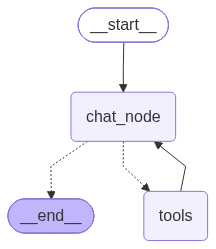

In [19]:
chatbot

In [20]:
result = chatbot.invoke(
    {
        "messages": [
            HumanMessage(
                content=(
                    "Using the pdf notes, explain how to find the ideal value of K in KNN"
                )
            )
        ]
    }
)

In [21]:
print(result['messages'][-1].content)

To find the ideal value of K in KNN, you need to determine the optimal number of neighbors (K) that will result in the best accuracy. Here's a step-by-step guide to help you find the ideal value of K:

1. **Collect data**: Gather a dataset with the following characteristics:
	* Features (X): numerical values that describe the characteristics of the data.
	* Target variable (y): the output variable that you want to predict.
2. **Split data**: Split your dataset into training (e.g., 80%) and testing sets (e.g., 20%).
3. **Choose a algorithm**: Select a KNN algorithm implementation, such as `sklearn.neighbors.KNeighbors` in Python.
4. **Tune K**: Use a grid search or random search to find the optimal value of K. You can use the `GridSearchCV` or `RandomizedSearchCV` class to perform the search.
5. **Evaluate**: Evaluate the performance of the model using metrics such as accuracy, precision, recall, F1-score, and mean squared error (MSE) on the testing set.

Here's an example code snippet 